<a href="https://colab.research.google.com/github/psh135230-design/BioAI_KU_2026/blob/claude/project-thread-ko8c9f/1115_8%EA%B0%9C%EC%95%94%EC%A2%85_%ED%86%B5%ED%95%A9%EB%B6%84%EC%84%9D_%EC%A0%84%EC%B2%B4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 8개 암종 통합 분석 전체 (Q1·Q2) — 11/15

- 입력: 파트너가 만든 `GSE154763_8cancers_merged_preserved_union.h5ad` (65,698세포 × 18,486유전자)와 `TableS5_angiogenesis_*.csv`.
- 이 노트북 하나로 0~9단계(전처리 → 통합 → C1QC+ 추출 → DC 정리 → 재군집 → Q1 비교·검정 → Q1 분류기 → Q2 혈관신생 → N 대 T → 견고성)를 끝까지 돌림.
- 저장된 출력은 Claude가 클라우드에서 같은 코드를 실행한 결과임. Colab에서 다시 돌리면 버전 차이로 군집 번호가 조금 달라질 수 있음.
- 각 단계: **코드 → 출력 → 개념 설명 → 결과 해석** 순서.
- 우리가 임의로 정한 기준값(50%, 5%, 2명, 상위 10%, CD163 50%)은 문헌 값이 아님. 셀 주석에 `(우리 기준)`으로 표시함.

## 한눈에 보는 결론 (11/15 실행)

| 질문 | 결과 | 근거 단계 |
|---|---|---|
| 데이터 준비 | 공통 11,102유전자, 암종별 정규화 척도를 1만으로 다시 맞춤 | 1 |
| 통합 | BBKNN 11군집, 환자·암종 쏠림 0. cDC1은 BBKNN에서 묻히고 Harmony에서 남음 | 2 |
| C1QC+ 규칙 | 19,195세포, 저자 Macro_C1QC 90.5% 회수. 실제로는 "C1Q 높은 대식세포 전체" | 3 |
| DC 정리 | 3,159세포 제거, 남은 cDC 4.1% | 4 |
| Q1 공통 대 특이 | 5개 상태 모두 6~8개 암종에 있음. 비율은 4개 상태에서 암종 간 차이(FDR 0.026) | 5·6 |
| Q1 분류기 | macro F1 0.298 (기준선 0.06~0.22). 암종 신호는 약함 | 7 |
| Q2 | 고점수 대식세포의 57%가 SPP1 음성. ESCA INHBA·KIDNEY FN1 = 논문 Fig 6E와 일치. NLRP3 대식세포가 새 후보(VCAN·CD44·VEGFA 때문) | 8 |
| N 대 T | 혈관신생 점수 차이 없음(p 0.43). 상태 비율은 T에서 SPP1 지질형 40% 대 N 9%, N에서 LYVE1 상주형 40% 대 T 10% | 9 |
| 견고성 | 상주형·염증형은 Harmony에서도 재현, 지질형·혼합형 경계는 방법에 따라 바뀜 | 10 |


## 0. 준비
Colab이면 드라이브를 연결하고 `DATA` 폴더에서 파일을 읽음. 파트너 공유 폴더 경로가 다르면 `DATA`만 고치면 됨.

In [1]:
import sys, os
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    import subprocess; subprocess.run('pip install -q bbknn harmonypy leidenalg igraph', shell=True)
    from google.colab import drive; drive.mount('/content/drive')
    DATA = '/content/drive/MyDrive/GSE154763_partner_results/'          # 합친 h5ad + TableS5 csv 5개가 있는 폴더
else:
    DATA = os.environ.get('DATA', '/mnt/project-files/')

import scanpy as sc, pandas as pd, numpy as np, bbknn, harmonypy, warnings
from collections import Counter
from importlib.metadata import version
from sklearn.metrics import adjusted_rand_score as ari, silhouette_score, f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from scipy.stats import wilcoxon, kruskal
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
sc.settings.verbosity = 0
OUT = 'results_1115'; os.makedirs(OUT, exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
print({p: version(p) for p in ['scanpy', 'anndata', 'bbknn', 'harmonypy', 'pandas', 'scikit-learn', 'leidenalg']})

# crosstab 대신 쓰는 표 함수 (Colab pandas 2.2.3 + Python 3.13 crosstab/unstack 오류 회피)
def _key(x): return (0, int(x), '') if x.isdigit() else (1, 0, x)
def xtab(rows, cols):
    r = [str(v) for v in rows]; c = [str(v) for v in cols]; cnt = Counter(zip(r, c))
    ri = sorted(set(r), key=_key); ci = sorted(set(c), key=_key)
    return pd.DataFrame([[cnt[(i, j)] for j in ci] for i in ri], index=ri, columns=ci)

def pct_pos(ad, genes, by):
    """군집별로 유전자가 켜진(>0) 세포 비율(%)"""
    return pd.DataFrame({g: pd.Series(ad[:, g].X.toarray().ravel() > 0, index=ad.obs_names)
                         .groupby(ad.obs[by].values).mean() * 100 for g in genes}).round(0)

{'scanpy': '1.13.0', 'anndata': '0.13.4', 'bbknn': '1.6.0', 'harmonypy': '2.1.0', 'pandas': '3.0.5', 'scikit-learn': '1.9.1', 'leidenalg': '0.12.0'}


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. 공통 유전자 + 다시 정규화

**개념**
- 합친 파일은 유전자 **합집합**이라, 어떤 암종에 없던 유전자는 0으로 채워져 있음. 이 0은 "발현 0"이 아니라 "측정 안 됨"임 → 분석은 8개 암종에 모두 있는 **공통 유전자**만 씀.
- GEO 값을 `expm1`로 풀어 세포별 합계를 보면, 암종 안에서는 모두 같고 암종끼리는 다름. 저자가 암종마다 "그 암종 세포 count 중앙값"을 목표로 정규화한 것으로 보임(scanpy `normalize_total`의 기본값이 중앙값). 그대로 합치면 암종 차이에 "척도 차이"가 섞임.
- 그래서 공통 유전자로 자른 뒤 `expm1 → 세포 합 1만 → log1p`로 모든 세포를 같은 척도로 맞춤. raw count 복원이 아니라 척도 통일임.

In [2]:
raw = sc.read_h5ad(DATA + 'GSE154763_8cancers_merged_preserved_union.h5ad')
s = pd.Series(np.asarray(raw.X.expm1().sum(axis=1)).ravel(), index=raw.obs_names)
chk = pd.DataFrame({'expm1 합(세포마다)': s.groupby(raw.obs['cancer'], observed=True).median().round(0),
                    '세포마다 차이(표준편차)': s.groupby(raw.obs['cancer'], observed=True).std().round(1),
                    'n_counts 중앙값': raw.obs.groupby('cancer', observed=True)['n_counts'].median()})
print(chk)
common = raw.var_names[raw.var['present_in_all']]
print('합집합', raw.n_vars, '→ 공통', len(common))
print('공통에서 빠진 주요 마커:', [g for g in ['KIT', 'TPSAB1', 'CPA3', 'EPCAM', 'LYVE1', 'XCR1', 'RPS4Y1'] if g not in common])
adata = raw[:, common].copy(); del raw
adata.X = adata.X.astype('float32').expm1()
sc.pp.normalize_total(adata, target_sum=1e4); sc.pp.log1p(adata)
adata.obs['celltype'] = adata.obs['MajorCluster'].astype(str).str.split('_', n=1).str[1]   # M09_Macro_C1QC → Macro_C1QC
print(adata.shape, '최댓값', round(float(adata.X.max()), 2))
print(xtab(adata.obs['celltype'], adata.obs['cancer']))

        expm1 합(세포마다)  세포마다 차이(표준편차)  n_counts 중앙값
cancer                                            
ESCA           7301.0            0.0        7303.0
KIDNEY         7931.0            0.0        7907.0
LYM           10310.0            0.0        9913.0
MYE            5803.0            0.0        5803.0
OV-FTC        10289.0            0.0       10249.0
PAAD           6955.0            0.0        6966.0
THCA           9944.0            0.0        9941.0
UCEC           8501.0            0.0        8496.0
합집합 18486 → 공통 11102
공통에서 빠진 주요 마커: ['KIT', 'TPSAB1', 'CPA3', 'EPCAM', 'LYVE1', 'XCR1', 'RPS4Y1']


(65698, 11102) 최댓값 8.56
               ESCA  KIDNEY  LYM   MYE  OV-FTC  PAAD  THCA  UCEC
Macro_C1QC     1101    1536   29  1005    1925  1023   443   865
Macro_FN1         0    1319    0     0       0     0     0     0
Macro_GPNMB       0    2264    0     0       0     0     0     0
Macro_IL1B        0    2363    0     0       0     0     0     0
Macro_INHBA     947       0    0     0       0     0  1100     0
Macro_ISG15       0       0  264     0       0     0   144   318
Macro_LYVE1    1217    1314    0     0       0     0   252   636
Macro_NLRP3    1560       0    0   151       0     0   889  1303
Macro_SPP1        0       0    0     0    1353   356   498  1072
Mast_KIT        539    1989    0     0       7   594    50   689
Mono_CD14       974    5352  141  2321     258   409   221  1844
Mono_CD14CD16     0       0    0  1608       0     0     0     0
Mono_CD16       384    7776  121  2083     160    55   285   350
cDC1_CLEC9A      75     211   12    42      17    11   135   170
c

### 결과 해석 (1)
- expm1 합이 암종 안에서는 표준편차 0으로 완전히 같고, 암종끼리는 5,803(MYE)~10,310(LYM)으로 다름. 값이 그 암종 n_counts 중앙값과 거의 같음(MYE는 정확히 일치) → 저자가 암종마다 다른 목표값으로 정규화했다는 근거임(추정이지만 숫자로 뒷받침됨).
- 그대로 합치면 LYM 세포가 MYE 세포보다 모든 유전자가 약 1.8배(10,310/5,803) 높게 보임. 다시 정규화해서 이 차이를 없앴음.
- 공통 유전자로 자르면 마스트세포 마커(KIT·TPSAB1·CPA3)와 LYVE1·EPCAM·XCR1이 빠짐 → 이 세포형들은 마커 대신 저자 라벨(`MajorCluster`)로 확인함.
- 저자 라벨 표: Macro_C1QC는 8개 암종 모두에 있음. 다른 대식세포 아형 이름은 암종마다 다름(저자가 암종별로 따로 이름 붙임).

## 2. 통합 3가지 비교 (보정 전 · BBKNN · Harmony)

**개념**
- 배치 키는 `patient_uid`(암종__환자, 47개). 같은 환자 문자열이 다른 암종에 4번 겹쳐서(P20181123, P20190404, P20190306, P20190122) 원래 `patient`를 쓰면 다른 암종 세포를 같은 배치로 묶게 됨.
- **BBKNN**: PCA는 그대로 두고, 이웃을 찾을 때 환자마다 같은 수만큼 뽑아 그래프를 고침. 원 논문(Cheng 2021) 방법이라 기준선.
- **Harmony**: 세포를 대략 묶은 뒤 묶음마다 환자 간 중심이 겹치도록 PCA 좌표를 반복해서 옮김.
- scVI는 raw count가 필요한데 GEO에 없어서 8개 암종에서는 제외.
- 평가: 한 환자/한 암종이 90% 넘는 군집 수, 환자 silhouette, 저자 라벨과의 ARI, 희귀 세포형(pDC, cDC1, 마스트, cDC3)이 따로 남는지.

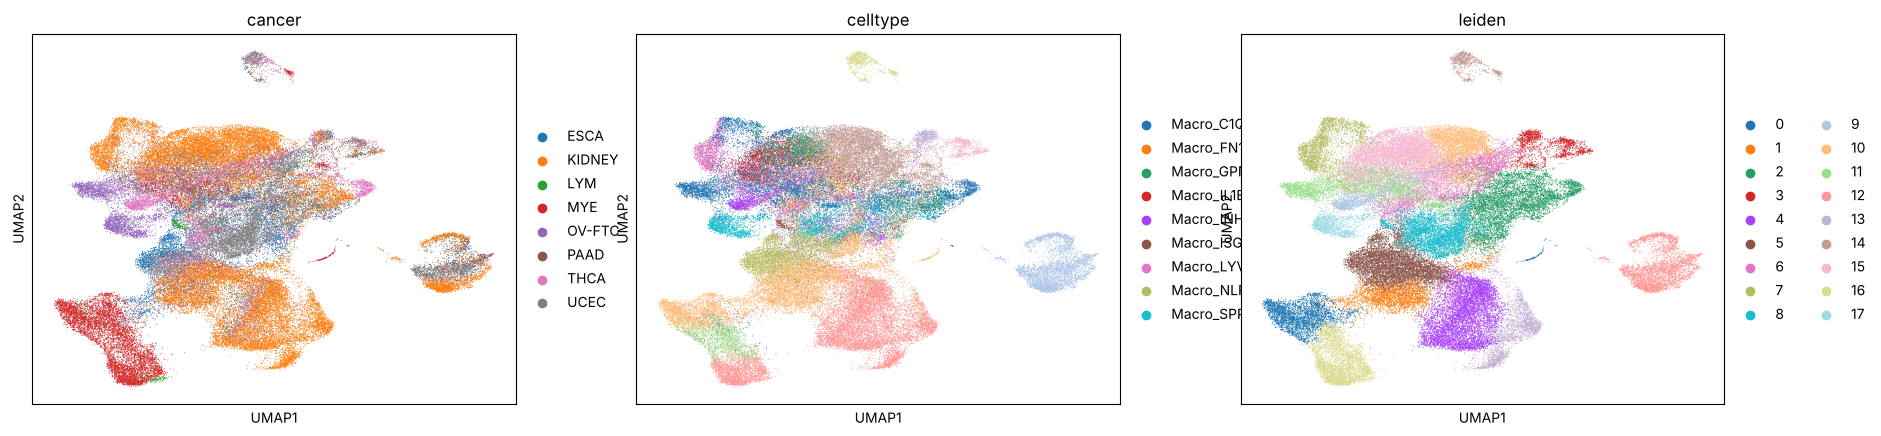

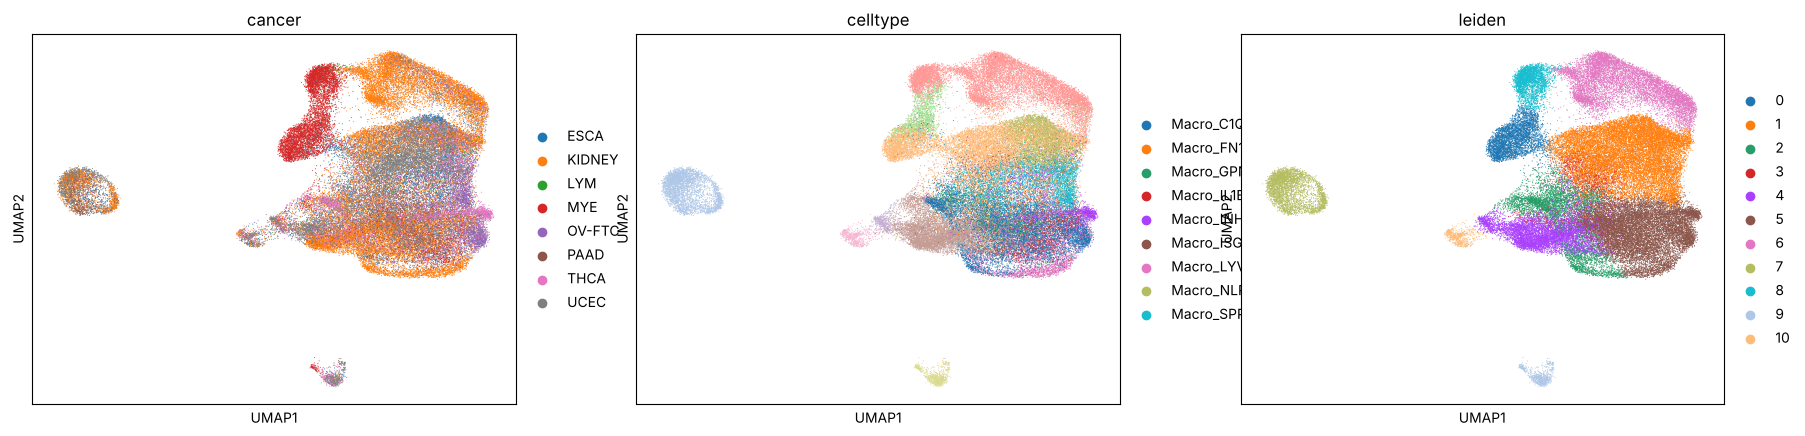

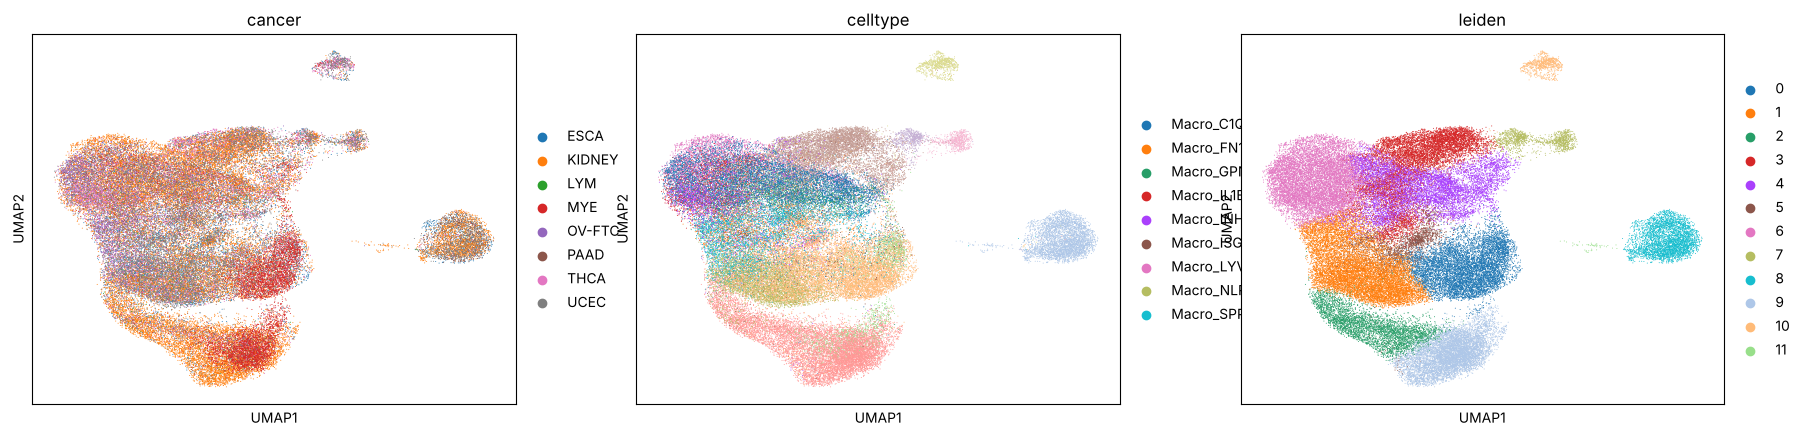

     방법  군집 수  한 환자 90%+ 군집  한 암종 90%+ 군집  환자 silhouette  저자 라벨 ARI
   none    18             1             4         -0.077      0.339
  bbknn    11             0             0         -0.077      0.367
harmony    12             0             1         -0.190      0.365
     방법         세포형 가장 많이 간 군집  그 군집에 간 수  세포형 전체  군집 크기
   none  pDC_LILRA4         14        748     786    757
   none cDC1_CLEC9A          3        641     673   1483
   none    Mast_KIT         12       3692    3868   3697
   none  cDC3_LAMP3          3        655     740   1483
  bbknn  pDC_LILRA4          9        748     786    757
  bbknn cDC1_CLEC9A          4        623     673   7367
  bbknn    Mast_KIT          7       3680    3868   3686
  bbknn  cDC3_LAMP3         10        632     740    649
harmony  pDC_LILRA4         10        745     786    766
harmony cDC1_CLEC9A          7        615     673   1338
harmony    Mast_KIT          8       3647    3868   3669
harmony  cDC3_LAMP3          7        662   

In [3]:
def recipe(ad, method='bbknn', batch='patient_uid', n_pcs=30, res=0.6):
    ad = ad.copy()
    sc.pp.highly_variable_genes(ad, n_top_genes=2000, flavor='seurat')
    sc.tl.pca(ad, n_comps=n_pcs, mask_var='highly_variable', random_state=0)
    if method == 'bbknn':
        bbknn.bbknn(ad, batch_key=batch, n_pcs=n_pcs)
    elif method == 'harmony':
        Z = harmonypy.run_harmony(ad.obsm['X_pca'], ad.obs, batch, random_state=0, verbose=False).Z_corr
        ad.obsm['X_harmony'] = np.asarray(Z if Z.shape[0] == ad.n_obs else Z.T)
        sc.pp.neighbors(ad, use_rep='X_harmony', n_neighbors=15, random_state=0)
    else:
        sc.pp.neighbors(ad, n_neighbors=15, n_pcs=n_pcs, random_state=0)
    sc.tl.leiden(ad, resolution=res, random_state=0, flavor='igraph', n_iterations=2, directed=False)
    sc.tl.umap(ad, random_state=0)
    return ad

rows, rare, res = [], [], {}
for m in ['none', 'bbknn', 'harmony']:
    ad = recipe(adata, method=m)
    cp = xtab(ad.obs['leiden'], ad.obs['patient_uid']); cc = xtab(ad.obs['leiden'], ad.obs['cancer'])
    X = ad.obsm['X_harmony' if m == 'harmony' else 'X_pca'][:, :30]
    rows.append({'방법': m, '군집 수': len(cp),
                 '한 환자 90%+ 군집': int(((cp.max(axis=1) / cp.sum(axis=1)) > 0.9).sum()),
                 '한 암종 90%+ 군집': int(((cc.max(axis=1) / cc.sum(axis=1)) > 0.9).sum()),
                 '환자 silhouette': round(silhouette_score(X, ad.obs['patient_uid'], sample_size=10000, random_state=0), 3),
                 '저자 라벨 ARI': round(ari(ad.obs['celltype'], ad.obs['leiden']), 3)})
    t = xtab(ad.obs['celltype'], ad.obs['leiden'])
    for ct in ['pDC_LILRA4', 'cDC1_CLEC9A', 'Mast_KIT', 'cDC3_LAMP3']:
        top = t.loc[ct].idxmax()
        rare.append({'방법': m, '세포형': ct, '가장 많이 간 군집': top, '그 군집에 간 수': t.loc[ct, top],
                     '세포형 전체': t.loc[ct].sum(), '군집 크기': t[top].sum()})
    fig = sc.pl.umap(ad, color=['cancer', 'celltype', 'leiden'], ncols=3, size=2, show=False, return_fig=True)
    fig.savefig(f'{OUT}/F1_{m}_umap.png', dpi=100, bbox_inches='tight'); plt.show()
    if m != 'none': res[m] = ad
    del ad
print(pd.DataFrame(rows).to_string(index=False))
print(pd.DataFrame(rare).to_string(index=False))
print('BBKNN 대 Harmony ARI', round(ari(res['bbknn'].obs['leiden'], res['harmony'].obs['leiden']), 3))

### 결과 해석 (2)
- 보정 전 18군집 중 한 환자가 90% 넘는 군집은 1개뿐임(MYE 혼자일 땐 9/14). 환자가 47명이라 한 명이 군집을 채우기 어려움. 대신 **한 암종 쏠림 군집이 4개** 있었고, BBKNN 후 0개, Harmony 후 1개가 됨.
- 환자로 보정했는데 암종 쏠림도 사라졌음 → 환자가 암종 안에 들어 있는 **중첩 설계**라서 환자 보정이 암종 차이 일부까지 지울 수 있음. Q1이 암종 차이를 묻기 때문에 이건 한계로 적음(11/2 강의 confounded design).
- 희귀 세포형: pDC·마스트는 세 방법 모두 깨끗한 단독 군집으로 남음. cDC1은 BBKNN에서 7,367세포짜리 큰 군집에 묻혔고, Harmony와 보정 전에서는 1,300~1,500세포 DC 군집에 남음 → DC 쪽은 Harmony가 더 잘 지킴.
- 저자 라벨 ARI는 BBKNN 0.367, Harmony 0.365로 거의 같음. 그래서 아래는 원 논문 방법인 BBKNN을 기준선으로 쓰고, 10단계에서 Harmony로 다시 확인함.

## 3. C1QC+ 대식세포 뽑기

**개념**
- 군집마다 CD163·C1QC·C1QA·APOE가 켜진 세포 비율(%)을 내고, 넷 다 50% 이상인 군집만 남김 `(우리 기준)`.
- C1QC·C1QA·APOE = Cheng 2021 Fig 1E의 Macro_C1QC 마커. CD163을 필수로 넣은 이유: C1q는 미성숙 수지상세포도 만들고(Castellano 2004 Blood), CD163은 DC에서 음성(Lau 2004 AJCP).
- 규칙이 맞는지는 저자 라벨(Macro_C1QC)을 얼마나 회수하는지로 확인함. BBKNN과 Harmony 둘 다 해 봄.

In [4]:
genes4 = ['CD163', 'C1QC', 'C1QA', 'APOE']
keep_cells = {}
for m in ['bbknn', 'harmony']:
    ad = res[m]
    pct = pct_pos(ad, genes4, 'leiden'); pct['세포수'] = ad.obs['leiden'].value_counts()
    pct['통과'] = (pct[genes4] >= 50).all(axis=1)
    inC = ad.obs['leiden'].isin(pct.index[pct['통과']]); isC = ad.obs['celltype'] == 'Macro_C1QC'
    keep_cells[m] = ad.obs_names[inC]
    print(f'===== {m}'); print(pct)
    print('통과 세포', int(inC.sum()), '| 저자 Macro_C1QC 회수율 %', round((isC & inC).sum() / isC.sum() * 100, 1),
          '| 통과 세포 중 저자 Macro_C1QC %', round((isC & inC).sum() / inC.sum() * 100, 1),
          '| 통과 세포 중 저자 Macro_* %', round((inC & ad.obs['celltype'].str.startswith('Macro')).sum() / inC.sum() * 100, 1))
    r = pd.DataFrame({'저자C1QC': isC.groupby(ad.obs['cancer'], observed=True).sum(),
                      '그중 통과': (isC & inC).groupby(ad.obs['cancer'], observed=True).sum()})
    r['회수율%'] = (r['그중 통과'] / r['저자C1QC'] * 100).round(1); print(r.T)
print(xtab(res['bbknn'].obs.loc[keep_cells['bbknn'], 'celltype'], res['bbknn'].obs.loc[keep_cells['bbknn'], 'cancer']))

===== bbknn
    CD163  C1QC  C1QA  APOE    세포수     통과
0    42.0   1.0   4.0   0.0   4048  False
1    77.0  15.0  18.0  18.0  16360  False
2    61.0  86.0  87.0  57.0   5486   True
3    49.0  36.0  41.0  18.0   1989  False
4    43.0  43.0  48.0  19.0   7367  False
5    81.0  96.0  97.0  72.0  13709   True
6    13.0   7.0  38.0   3.0   8781  False
7     1.0   3.0   3.0  34.0   3686  False
8     2.0   8.0  29.0   0.0   2866  False
9     1.0   1.0   2.0   1.0    757  False
10    1.0  10.0   9.0  23.0    649  False
통과 세포 19195 | 저자 Macro_C1QC 회수율 % 90.5 | 통과 세포 중 저자 Macro_C1QC % 37.4 | 통과 세포 중 저자 Macro_* % 88.8
cancer    ESCA  KIDNEY    LYM     MYE  OV-FTC    PAAD   THCA   UCEC
저자C1QC  1101.0  1536.0   29.0  1005.0  1925.0  1023.0  443.0  865.0
그중 통과    739.0  1504.0   29.0   789.0  1903.0   983.0  442.0  784.0
회수율%      67.1    97.9  100.0    78.5    98.9    96.1   99.8   90.6


===== harmony
    CD163  C1QC  C1QA  APOE    세포수     통과
0    59.0   4.0   7.0   3.0   7767  False
1    79.0  17.0  20.0  20.0  10757  False
2    17.0   9.0  38.0   3.0   4264  False
3    53.0  50.0  56.0  28.0   8377  False
4    63.0  87.0  87.0  66.0   8515   True
5    59.0  14.0  21.0  12.0   2194  False
6    83.0  97.0  97.0  65.0  10599   True
7     1.0  10.0   9.0  14.0   1338  False
8     1.0   3.0   3.0  34.0   3669  False
9     6.0   6.0  33.0   2.0   7331  False
10    1.0   1.0   2.0   1.0    766  False
11   41.0  49.0  55.0  46.0    121  False
통과 세포 19114 | 저자 Macro_C1QC 회수율 % 89.1 | 통과 세포 중 저자 Macro_C1QC % 36.9 | 통과 세포 중 저자 Macro_* % 87.8
cancer    ESCA  KIDNEY   LYM     MYE  OV-FTC    PAAD   THCA   UCEC
저자C1QC  1101.0  1536.0  29.0  1005.0  1925.0  1023.0  443.0  865.0
그중 통과    871.0  1501.0  27.0   733.0  1803.0   936.0  436.0  753.0
회수율%      79.1    97.7  93.1    72.9    93.7    91.5   98.4   87.1
               ESCA  KIDNEY  LYM  MYE  OV-FTC  PAAD  THCA  UCEC
Macro_C1QC

### 결과 해석 (3)
- BBKNN에서 2개 군집(19,195세포)이 통과했고, 저자 Macro_C1QC의 90.5%를 회수함. Harmony도 89.1%로 비슷함 → 규칙은 방법에 크게 좌우되지 않음.
- 그런데 통과 세포 중 저자 Macro_C1QC는 37%뿐이고, 저자 대식세포 전체(Macro_*)가 89%임. 즉 8개 암종을 합치면 C1QC·C1QA·APOE·CD163은 "C1QC 아형"만이 아니라 대식세포 대부분이 공유하는 표지임. 우리 규칙이 뽑는 건 정확히는 **C1Q가 높은 대식세포 전체**이고, Q1의 정의도 이렇게 적어야 함.
- ESCA(67%)와 MYE(79%)의 회수율이 낮음. 이 두 암종의 Macro_C1QC 일부가 단핵구 쪽 군집에 들어갔다는 뜻이고, 원 논문에서도 MYE는 혈액 단핵구가 많은 데이터임.
- cDC2가 716(KIDNEY)·356(THCA) 등 합계 약 1,600개 섞임 → 4단계에서 정리함.

## 4. 대식세포만 재군집 + DC 섞임 정리

**개념**
- 재군집(Hu 2023 틀): 대식세포만 남기고 HVG·PCA·BBKNN을 다시 계산하면, 대식세포 안의 차이를 잡는 유전자가 새로 뽑힘. Hu 2023 골수계 조건(PC 15, res 0.4)을 따름.
- DC 정리: 군집 단위로 자르면 경계 세포(cDC2)가 따라옴. 해상도를 1.0으로 높여 작은 하위군집으로 나눈 뒤, **CD163 50% 미만 또는 CD1C 30% 이상** 하위군집을 DC 섞임으로 보고 뺌 `(우리 기준)`. Hu 2023이 "두 계통 마커가 같이 나오는 군집 제거"를 한 것과 같은 단계.
- 뺀 뒤 다시 HVG·PCA·BBKNN → res 0.4/0.6 군집 → 두 해상도 ARI로 안정성 확인.

In [5]:
def recluster(mac, res_list=(0.4, 0.6)):
    n = mac.obs['patient_uid'].value_counts()
    mac = mac[mac.obs['patient_uid'].isin(n[n >= 10].index)].copy()            # 대식세포 10개 미만 환자 제외 (Hu 2023, BBKNN도 배치당 최소 세포 필요)
    sc.pp.highly_variable_genes(mac, n_top_genes=2000, flavor='seurat')
    sc.tl.pca(mac, n_comps=30, mask_var='highly_variable', random_state=0)
    bbknn.bbknn(mac, batch_key='patient_uid', n_pcs=15, neighbors_within_batch=3)      # PC 15 = Hu 2023
    for r in res_list:
        sc.tl.leiden(mac, resolution=r, random_state=0, key_added=f'mac_r{r}', flavor='igraph', n_iterations=2, directed=False)
    return mac

mac0 = recluster(res['bbknn'][keep_cells['bbknn']].copy(), res_list=(1.0,))
chk = pct_pos(mac0, ['CD163', 'C1QC', 'APOE', 'CD1C', 'FCER1A', 'CLEC10A'], 'mac_r1.0')
chk['세포수'] = mac0.obs['mac_r1.0'].value_counts()
chk['저자 cDC %'] = (mac0.obs['celltype'].str.startswith('cDC').groupby(mac0.obs['mac_r1.0']).mean() * 100).round(0)
chk['제거'] = (chk['CD163'] < 50) | (chk['CD1C'] >= 30)                                 # (우리 기준)
print(chk)
drop = mac0.obs['mac_r1.0'].isin(chk.index[chk['제거']])
isdc = mac0.obs['celltype'].str.startswith('cDC')
print('제거', int(drop.sum()), '세포 | 저자 cDC', int(isdc.sum()), '개 중', int((drop & isdc).sum()), '개 제거 | 저자 Macro_* 제거',
      int((drop & mac0.obs['celltype'].str.startswith('Macro')).sum()))

mac = recluster(mac0[~drop].copy())
sc.tl.umap(mac, random_state=0)
print('남은 세포', mac.n_obs, '| res0.4 상태 수', mac.obs['mac_r0.4'].nunique(), '| res0.6', mac.obs['mac_r0.6'].nunique(),
      '| ARI(0.4 대 0.6)', round(ari(mac.obs['mac_r0.4'], mac.obs['mac_r0.6']), 3))
print('남은 세포 중 저자 cDC %', round(mac.obs['celltype'].str.startswith('cDC').mean() * 100, 1))

    CD163   C1QC  APOE  CD1C  FCER1A  CLEC10A   세포수  저자 cDC %     제거
0    89.0  100.0  54.0   4.0    13.0     36.0  1585       2.0  False
1    38.0   75.0  39.0  38.0    35.0     54.0  1899      42.0   True
2    53.0   83.0  84.0   5.0     2.0     19.0  1498       2.0  False
3    94.0  100.0  84.0   0.0     3.0     16.0  1609       0.0  False
4    92.0  100.0  30.0   4.0    11.0     58.0   485       5.0  False
5    61.0   75.0  22.0  38.0    74.0     69.0  1260      16.0   True
6    78.0   98.0  79.0  12.0    38.0     41.0  1861       6.0  False
7    76.0   98.0  69.0  20.0    59.0     59.0  1184      12.0  False
8    84.0   98.0  88.0   6.0    14.0     38.0  1695       1.0  False
9    76.0   97.0  93.0  15.0    37.0     45.0  2752      10.0  False
10   74.0   99.0  93.0   3.0     2.0     17.0  1590       0.0  False
11   96.0  100.0  33.0   1.0     9.0     30.0  1777       0.0  False
제거 3159 세포 | 저자 cDC 1645 개 중 989 개 제거 | 저자 Macro_* 제거 1944


남은 세포 16014 | res0.4 상태 수 5 | res0.6 7 | ARI(0.4 대 0.6) 0.599
남은 세포 중 저자 cDC % 4.1


### 결과 해석 (4)
- res 1.0으로 12개 하위군집을 만들었더니, 군집 1(CD163 38%, 저자 cDC 42%)과 군집 5(CD1C 38%, FCER1A 74%)가 DC 쪽 특징을 보였음 → 제거 규칙에 걸림.
- 3,159세포를 뺐고, 저자 cDC 1,645개 중 989개(60%)가 빠짐. 대신 저자 Macro_* 1,944개도 같이 빠졌음. DC와 대식세포의 경계가 연속적이라 완벽하게 가를 수는 없음.
- 정리 후 16,014세포, res 0.4에서 5개 상태, 0.4 대 0.6 ARI 0.599. 남은 세포 중 저자 cDC는 4.1%임(정리 전 약 8.6%). 남은 DC 섞임은 한계로 적음.

## 5. 세부 상태 이름 붙이기 (마커)

**개념**
- 상태별로 나머지와 비교해 **Wilcoxon 순위합 검정**으로 마커를 찾음. 단일세포 발현은 0이 많고 정규분포가 아니라서 평균 대신 순위를 씀. 파트너 비교에서 t-test와 상위 20개 겹침이 55%였기 때문에 하나(Wilcoxon)로 통일함.
- 리보솜·미토콘드리아·Ig·스트레스 유전자는 이름 붙이기에서 뺌(기존 필터와 같음).
- 이름은 Cheng 2021 Fig 1E 마커(NLRP3/IL1B, LYVE1, C1QC/APOE)와 겹치는지로 정당화함. 이름은 "후보"임.

group
0    TXNIP, SLC40A1, MS4A6A, ITM2B, C1QA, GPR34, FO...
1    ATF3, KLF6, KLF2, SGK1, TSC22D3, NR4A2, GADD45...
2    CCL3, CCL4, IL1B, CCL3L3, CCL4L2, BCL2A1, ICAM...
3    HLA-DPB1, HLA-DRA, HLA-DRB5, SDS, LITAF, AREG,...
4    LGALS1, MIF, SERF2, GAPDH, S100A11, CAPG, CSTB...


    C1QC  APOE  APOC1  GPNMB  IL1B  NLRP3   CCL3  VEGFA  INHBA  SEPP1  MRC1  FOLR2  SPP1   FN1  ISG15  MKI67  CD1C
0  100.0  51.0   36.0   43.0  17.0   25.0   36.0    8.0    0.0   84.0  81.0   80.0   7.0   5.0   24.0    1.0   5.0
1   99.0  52.0   41.0   36.0  68.0   59.0   86.0   34.0    3.0   80.0  75.0   76.0  12.0   8.0   26.0    0.0   5.0
2  100.0  86.0   76.0   57.0  99.0   93.0  100.0   70.0   12.0   79.0  65.0   74.0  27.0  16.0   44.0    1.0   2.0
3   97.0  85.0   81.0   51.0  81.0   73.0   60.0   64.0   15.0   35.0  35.0   29.0  16.0  23.0   44.0    1.0  14.0
4   90.0  88.0   88.0   77.0  41.0   25.0   44.0   38.0   12.0   18.0  46.0   32.0  73.0  37.0   59.0    3.0   4.0


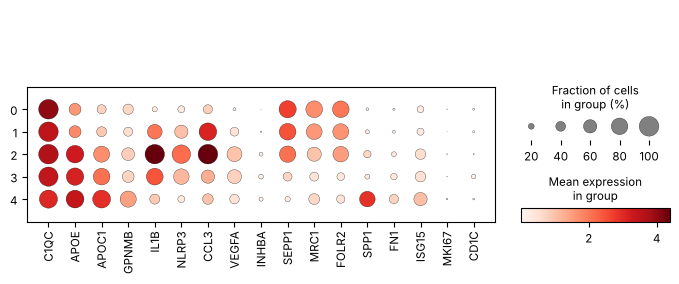

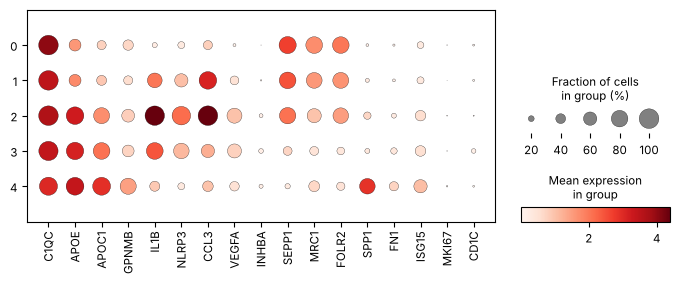

   Macro_C1QC  Macro_FN1  Macro_GPNMB  Macro_IL1B  Macro_INHBA  Macro_ISG15  Macro_LYVE1  Macro_NLRP3  Macro_SPP1  Mast_KIT  Mono_CD14  Mono_CD14CD16  Mono_CD16  cDC1_CLEC9A  cDC2_CD1C  cDC3_LAMP3  \
0        1043          0          141          18            0            1          489            0           1         2          5              1          0            0         52           0   
1         978          1           52         582           42            2         1627            5          28         6         21             38          0            0         64           0   
2        1645         33            5         636           84            8          352            6         143         6          3              1          2            0          9           2   
3        1328        360         1376         895          149           73          366           12         105        45         57             10         15            1        472           8   


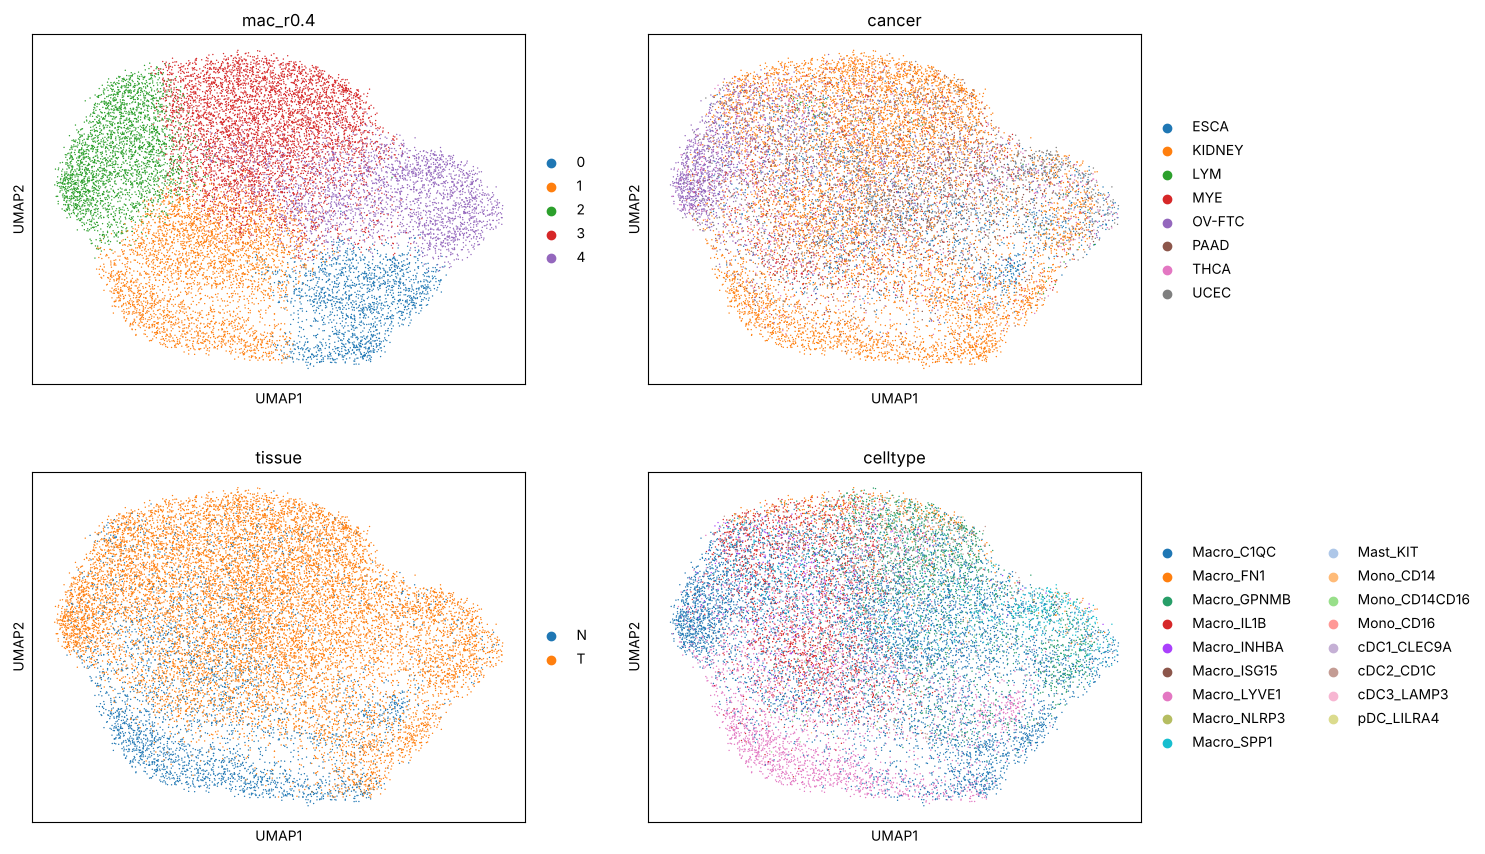

In [6]:
sc.tl.rank_genes_groups(mac, 'mac_r0.4', method='wilcoxon')
df = sc.get.rank_genes_groups_df(mac, group=None)
df = df[(df['logfoldchanges'] > 0) & ~df['names'].str.match(r'^(RP[SL]|MT-|IG[HKL]|HSPA|HSPH|DNAJ|FOS|JUN|EGR1|IER|DUSP1)')]
top = df.groupby('group', observed=True).head(10).groupby('group', observed=True)['names'].apply(lambda x: ', '.join(x))
print(top.to_string())
show = ['C1QC', 'APOE', 'APOC1', 'GPNMB', 'IL1B', 'NLRP3', 'CCL3', 'VEGFA', 'INHBA', 'SEPP1', 'MRC1', 'FOLR2', 'SPP1', 'FN1', 'ISG15', 'MKI67', 'CD1C']
show = [g for g in show if g in mac.var_names]
print(pct_pos(mac, show, 'mac_r0.4'))
fig = sc.pl.dotplot(mac, show, groupby='mac_r0.4', show=False, return_fig=True); fig.savefig(f'{OUT}/F3_mac_states_dotplot.png', dpi=110, bbox_inches='tight'); fig.show()
print(xtab(mac.obs['mac_r0.4'], mac.obs['celltype']))
print(xtab(mac.obs['mac_r0.4'], mac.obs['tissue']))
fig = sc.pl.umap(mac, color=['mac_r0.4', 'cancer', 'tissue', 'celltype'], ncols=2, size=4, show=False, return_fig=True)
fig.savefig(f'{OUT}/F2_mac_states_umap.png', dpi=100, bbox_inches='tight'); plt.show()

아래 셀의 `NAMES`는 위 마커 출력을 보고 정한 이름임. Colab에서 번호가 바뀌면 마커를 보고 다시 맞출 것.

In [7]:
NAMES = {'0': 'FOLR2_resident', '1': 'KLF2_LYVE1_resident', '2': 'IL1B_CCL3_inflam', '3': 'HLAII_mixed', '4': 'SPP1_APOC1_lipid'}   # 위 마커 보고 정한 이름 (후보)
mac.obs['state'] = mac.obs['mac_r0.4'].astype(str).map(lambda x: f'{x}_' + NAMES.get(x, '?'))
print(mac.obs['state'].value_counts())

state
3_HLAII_mixed            5273
1_KLF2_LYVE1_resident    3447
2_IL1B_CCL3_inflam       2935
4_SPP1_APOC1_lipid       2606
0_FOLR2_resident         1753
Name: count, dtype: int64


### 결과 해석 (5) 상태 이름
| 상태 | 마커 근거 | 저자 라벨 | 조직 | 이름 |
|---|---|---|---|---|
| 0 | SLC40A1, GPR34, FOLR2 80%, SEPP1 84%, MRC1 81%, IL1B 17% | C1QC, LYVE1 | T 1,104 / N 649 | FOLR2 상주형 |
| 1 | ATF3, KLF2, KLF6, NR4A2 (즉시 초기 유전자), SEPP1·FOLR2 높음 | **LYVE1 1,627**, IL1B | **N 1,938 > T 1,509** | KLF2·LYVE1 상주형 |
| 2 | CCL3, CCL4, IL1B 99%, NLRP3 93%, **VEGFA 70%** | C1QC, IL1B | T 2,520 | IL1B·CCL3 염증형 |
| 3 | HLA-DPB1, HLA-DRA, SDS, AREG / CD1C 14% | GPNMB 1,376, IL1B 895, **cDC2 472** | T 4,765 | HLA-II 높은 혼합형 |
| 4 | LGALS1, MIF, CSTB, **SPP1 73%**, APOC1 88%, GPNMB 77% | C1QC, SPP1 487, GPNMB 403 | T 2,448 / N 158 | SPP1·APOC1 지질형 |

- 이름은 Cheng 2021 Fig 1E(Macro_LYVE1, Macro_NLRP3·IL1B, Macro_SPP1)와 겹치는 마커로 붙인 **후보**임.
- 상태 1은 ATF3·FOS계 즉시 초기 유전자가 위에 있어서, 일부는 조직 해리 스트레스 신호일 수 있음(마커 필터에서 FOS·JUN·EGR1은 뺐지만 ATF3·KLF는 남겼음).
- 상태 3은 cDC2가 가장 많이 남은 곳이라 해석할 때 조심해야 함.

## 6. Q1: 세부 상태는 암종 공통인가, 특이한가

**개념**
- 비율은 **환자마다 먼저** 계산함(T 조직, 대식세포 10개 이상 환자만, Hu 2023 기준). 세포를 다 합치면 KIDNEY(전체의 44%)나 세포 많은 환자 한 명이 결과를 정해 버림. 환자 = 반복 단위(11/2 강의 "Cells, Samples, Donors").
- **공통성**: 상태가 한 암종 안에서 2명 이상 환자에게 5% 넘게 있으면 "그 암종에 있음" `(우리 기준)`.
- **암종 차이 검정**: 상태마다 환자별 비율을 암종 8그룹으로 나눠 **Kruskal–Wallis**(3그룹 이상용 순위 검정) → 상태 수만큼 검정했으니 **FDR(Benjamini–Hochberg)** 보정. Hu 2023의 그룹 비교 방식(순위 검정 + FDR)을 따름.
- **Ro/e**(관찰/기대): Cheng 2021이 조직 분포에 쓴 지표. 1보다 크면 그 암종에 많음. 세포 단위라 환자 불균형에 약해서 참고용.

환자 수 43
{'ESCA': 7, 'KIDNEY': 6, 'LYM': 3, 'MYE': 2, 'OV-FTC': 2, 'PAAD': 6, 'THCA': 9, 'UCEC': 8}


상태가 5% 넘는 환자 수
        0_FOLR2_resident  1_KLF2_LYVE1_resident  2_IL1B_CCL3_inflam  3_HLAII_mixed  4_SPP1_APOC1_lipid  환자수
ESCA                   2                      3                   1              6                   7    7
KIDNEY                 4                      5                   4              4                   1    6
LYM                    2                      1                   0              3                   3    3
MYE                    1                      2                   2              2                   1    2
OV-FTC                 0                      1                   1              2                   1    2
PAAD                   3                      6                   5              6                   6    6
THCA                   6                      8                   8              8                   7    9
UCEC                   0                      4                   4              8                   8    8
상태가 "있는" 암종 수

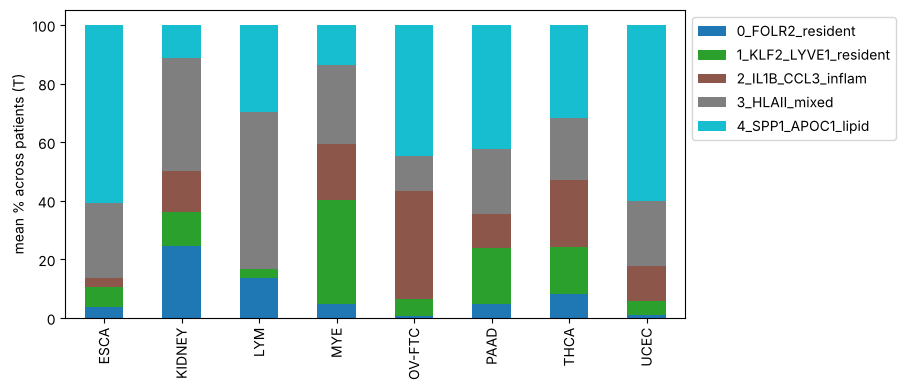

In [8]:
T = mac.obs[mac.obs['tissue'] == 'T']
ct = xtab(T['patient_uid'], T['state']); ct = ct[ct.sum(axis=1) >= 10]
frac = ct.div(ct.sum(axis=1), axis=0) * 100
cancer = pd.Series([i.split('__')[0] for i in frac.index], index=frac.index)
print('환자 수', len(frac)); print(cancer.value_counts().sort_index().to_dict())
present = pd.concat([(frac >= 5).groupby(cancer).sum(), cancer.value_counts().rename('환자수')], axis=1)
print('상태가 5% 넘는 환자 수'); print(present)
print('상태가 "있는" 암종 수(2명 이상, 환자 1~2명 암종은 1명 이상):')
need = cancer.value_counts().map(lambda n: 1 if n <= 2 else 2)
print(((frac >= 5).groupby(cancer).sum().ge(need, axis=0)).sum())
mean = frac.groupby(cancer).mean().round(1); print('암종별 환자 평균 비율(%)'); print(mean)
kw = []
for st in frac.columns:
    groups = [frac.loc[cancer == c, st].values for c in sorted(cancer.unique())]
    kw.append({'상태': st, 'H': round(kruskal(*groups).statistic, 2), 'p': kruskal(*groups).pvalue})
kw = pd.DataFrame(kw); kw['FDR'] = multipletests(kw['p'], method='fdr_bh')[1]; print(kw.round(4).to_string(index=False))
o = xtab(T['state'], T['cancer']).astype(float)
roe = o / (np.outer(o.sum(axis=1), o.sum(axis=0)) / o.values.sum()); print('Ro/e'); print(roe.round(2))
frac.to_csv(f'{OUT}/T_patient_x_state.csv')
ax = mean.plot.bar(stacked=True, figsize=(8, 4), colormap='tab10'); ax.set_ylabel('mean % across patients (T)'); ax.legend(bbox_to_anchor=(1, 1))
plt.savefig(f'{OUT}/F4_state_fraction_by_cancer.png', dpi=100, bbox_inches='tight'); plt.show()

### 결과 해석 (6) Q1
- **공통성**: 5개 상태 모두 6~8개 암종에서 "있음" 기준을 통과함. HLA-II 혼합형은 8개 모두, SPP1 지질형·KLF2 상주형은 7개, FOLR2 상주형·IL1B 염증형은 6개였음. 상태 자체는 대부분 암종에 공통으로 있음.
- **암종 차이**: 환자별 비율을 Kruskal–Wallis로 검정하면 5개 중 4개 상태가 암종 간에 다름(FDR 0.026). HLA-II 혼합형만 차이 없음(FDR 0.36).
  - SPP1 지질형: ESCA·UCEC에서 환자 평균 60%, KIDNEY 11% (Ro/e ESCA 2.98, UCEC 2.47, PAAD 2.18)
  - FOLR2 상주형: KIDNEY 24% (Ro/e 1.69), 나머지 1~14%
  - IL1B 염증형: OV-FTC 37% (Ro/e 3.09), LYM 0%
  - KLF2·LYVE1 상주형: MYE 35% (Ro/e 2.91), PAAD 19%
- **Q1 결론 문장(후보)**: "C1Q 높은 대식세포 안의 세부 상태는 대부분 8개 암종에 공통으로 존재했지만, 상태별 비율은 암종마다 유의하게 달랐다(5개 중 4개 상태, Kruskal–Wallis FDR < 0.05)."
- 주의: MYE·OV-FTC는 환자 2명, LYM 3명이라 검정력이 낮고 비율이 한두 명 값에 좌우됨. ESCA의 SPP1 지질형 60%는 원 논문이 ESCA를 "SPP1+ TAM이 없는 암종"으로 분류한 것과 어긋나 보이지만, 우리 상태 4는 SPP1 하나가 아니라 APOC1·GPNMB·LGALS1 지질 대사 상태 전체라서 같은 것이 아님(상태 4 안 SPP1 양성은 73%).

## 7. Q1 분류기: 대식세포 발현으로 암종을 맞힐 수 있나

**개념**
- **linear probe**: 이미 만든 표현(PCA 30)에 가장 단순한 선형 분류기(로지스틱 회귀)만 얹어서, 표현 안에 암종 정보가 "들어 있는지" 봄(11/9 강의 21쪽).
- **환자 하나씩 빼기**: 같은 환자 세포가 학습과 시험에 다 있으면 암종이 아니라 환자를 외워서 맞힘. `patient_original`로 묶어서 겹치는 문자열(P20190122 MYE·THCA 등)은 같이 빠짐.
- **누수 방지**: 시험 환자 세포가 PCA에도 들어가면 안 되므로, 폴드마다 학습 세포로만 HVG 행렬에 PCA를 다시 맞추고 시험 세포는 그 축에 투영함.
- `class_weight='balanced'`: KIDNEY가 수십 배 많아서 가중치 없이는 다 KIDNEY라고 해도 점수가 높게 나옴.
- **macro F1**: 암종마다 F1(정밀도·재현율 조화평균)을 내고 단순 평균 → 작은 암종도 같은 무게(11/9 강의 29쪽).
- **기준선**: 환자마다 암종 라벨을 무작위로 섞고 같은 평가 → "우연으로 나오는 점수".

In [9]:
b = mac[mac.obs['tissue'] == 'T']
Xh = b[:, b.var['highly_variable']].X.toarray()
y, g = b.obs['cancer'].astype(str).values, b.obs['patient_original'].astype(str).values
def lopo(y_use):
    pred = np.empty(len(y_use), dtype=object)
    for p in np.unique(g):
        te = g == p
        pca = PCA(n_components=30, random_state=0).fit(Xh[~te])                     # 학습 환자만으로 PCA
        clf = LogisticRegression(max_iter=3000, class_weight='balanced').fit(pca.transform(Xh[~te]), y_use[~te])
        pred[te] = clf.predict(pca.transform(Xh[te]))
    return pred
pred = lopo(y)
labs = sorted(set(y))
print('세포', len(y), '| 환자 문자열', len(np.unique(g)), '| macro F1', round(f1_score(y, pred, average='macro'), 3))
print('암종별 F1', dict(zip(labs, np.round(f1_score(y, pred, average=None, labels=labs), 2))))
cm = pd.DataFrame(confusion_matrix(y, pred, labels=labs), index=labs, columns=labs)
print('행 = 정답, 열 = 예측 (%)'); print((cm.div(cm.sum(axis=1), axis=0) * 100).round(0))
rng = np.random.default_rng(0); pats = pd.Series(y, index=g).groupby(level=0).first()
base = []
for k in range(3):
    ys = pd.Series(rng.permutation(pats.values), index=pats.index).reindex(g).values
    base.append(round(f1_score(ys, lopo(ys), average='macro'), 3))
print('라벨 섞은 기준선 macro F1', base)

세포 12346 | 환자 문자열 40 | macro F1 0.298
암종별 F1 {'ESCA': np.float64(0.43), 'KIDNEY': np.float64(0.54), 'LYM': np.float64(0.44), 'MYE': np.float64(0.19), 'OV-FTC': np.float64(0.03), 'PAAD': np.float64(0.36), 'THCA': np.float64(0.21), 'UCEC': np.float64(0.17)}
행 = 정답, 열 = 예측 (%)
        ESCA  KIDNEY   LYM   MYE  OV-FTC  PAAD  THCA  UCEC
ESCA    58.0     2.0   0.0   1.0     6.0  11.0  11.0  11.0
KIDNEY   5.0    43.0   0.0   3.0     6.0   8.0  11.0  24.0
LYM     12.0     0.0  42.0  27.0     0.0   2.0   5.0  12.0
MYE      2.0     9.0   1.0  14.0     0.0   9.0  57.0   7.0
OV-FTC  10.0    15.0   0.0   0.0     2.0  14.0  39.0  19.0
PAAD    20.0     5.0   0.0   3.0     2.0  44.0  18.0   8.0
THCA     8.0     5.0   1.0   7.0     3.0   8.0  62.0   6.0
UCEC    10.0    40.0   1.0   1.0     5.0   9.0   5.0  29.0


라벨 섞은 기준선 macro F1 [0.057, 0.13, 0.224]


### 결과 해석 (7) Q1 분류기
- 학습 환자만으로 PCA를 맞춘 정직한 평가에서 **macro F1 0.298**. 라벨을 섞은 기준선은 0.057·0.130·0.224(3번). 기준선보다 높지만 차이가 크지 않음(세 번째 섞기와는 0.07 차이).
- 첫 가이드(PCA를 전체 세포로 한 번 계산, DC 정리 전 14,972세포)에서는 0.398이었음. 이번엔 누수 방지와 DC 정리가 동시에 바뀌어서 0.1 하락의 원인을 하나로 나눌 수는 없음. 다만 이번 값이 더 보수적인 평가임.
- 잘 맞히는 암종: ESCA(58% 정답), THCA(62%), PAAD·KIDNEY·LYM(42~44%). 못 맞히는 암종: OV-FTC(2%, 학습용 환자 1명뿐), MYE(14%, 57%가 THCA로 감), UCEC(29%, 40%가 KIDNEY로 감).
- 해석: 6단계와 같은 이야기임. 상태가 공통이고 비율만 달라서, 세포 하나의 발현만 보고 암종을 맞히기는 어려움. "대식세포가 암종마다 완전히 다른 세포"라기보다 "같은 상태들을 다른 비율로 가진다"에 가까움.
- MYE→THCA 혼동은 흥미롭지만(P20190122가 MYE·THCA 둘 다에 있음), 이 평가에서 두 암종의 P20190122는 같이 빠졌기 때문에 같은 사람이라는 증거로 쓸 수는 없음.

## 8. Q2: SPP1이 아닌 혈관신생 대식세포

**개념**
- 점수: Cheng 2021 Table S5 혈관신생 25개 중 **8개 암종 공통 19개에서 SPP1을 뺀 18개**. LYM은 6개가 측정 안 됐고, SPP1이 목록에 있으면 SPP1+ 세포가 자동으로 높아져서 "SPP1 말고"를 볼 수 없음. 원 논문 시그니처를 고친 추가 분석용 목록임.
- `score_genes` = 18개 평균 발현 − 발현량이 비슷한 무작위 대조 유전자 평균. 0보다 크면 이 18개가 평균적인 유전자보다 더 켜져 있다는 뜻.
- 대식세포 집합은 저자 라벨 `Macro_*`(Q2는 모든 대식세포 아형을 봐야 해서 C1QC+만 쓰지 않음), T 조직.
- 아형 점수는 환자 평균(10세포 이상)으로 냄. 그리고 점수 상위 10% `(우리 기준)` 중 SPP1 음성 세포가 어느 아형에서 왔는지 봄. 20%로 바꿔도 같은지 확인.
- 논문 Fig 6E: SPP1+ TAM이 없는 암종의 대체 아형 = ESCA INHBA+, KIDNEY FN1+. 이 둘이 맞으면 우리 계산이 논문과 같은 방향이라는 검증이 됨.
- 점수는 발현 기반이라 실제 혈관 형성 기능의 증거는 아님(논문도 발현만 봄).

In [10]:
G18 = pd.read_csv(DATA + 'TableS5_angiogenesis_common_without_SPP1.csv')['gene'].tolist()
G25 = pd.read_csv(DATA + 'TableS5_angiogenesis_original_25genes.csv')['gene'].tolist()
print(len(G18), G18)
sc.tl.score_genes(adata, G18, score_name='angio18', random_state=0)
adata.obs['SPP1pos'] = adata[:, 'SPP1'].X.toarray().ravel() > 0
macT = adata.obs[adata.obs['celltype'].str.startswith('Macro') & (adata.obs['tissue'] == 'T')].copy()
print('T 대식세포', len(macT))
print('SPP1 양성 %', (macT.groupby('cancer', observed=True)['SPP1pos'].mean() * 100).round(1).to_dict())
pm = macT.groupby(['cancer', 'celltype', 'patient_uid'], observed=True)['angio18'].agg(['size', 'mean']).reset_index()
pm = pm[pm['size'] >= 10]
summ = pm.groupby(['cancer', 'celltype'])['mean'].agg(환자수='size', 점수='mean').round(3).reset_index()
print(summ.sort_values(['cancer', '점수'], ascending=[True, False]).to_string(index=False))
for q in [0.9, 0.8]:
    thr = macT['angio18'].quantile(q); hi = macT[macT['angio18'] >= thr]
    neg = hi[~hi['SPP1pos']]
    t = neg.groupby(['cancer', 'celltype'], observed=True).size().rename('n').reset_index()
    t['%'] = (t['n'] / t.groupby('cancer')['n'].transform('sum') * 100).round(0)
    print(f'\n상위 {round((1-q)*100)}% (기준 {thr:.3f}, {len(hi)}세포) 중 SPP1 음성 {round(len(neg)/len(hi)*100,1)}%  → 암종별 상위 2 아형')
    print(t.sort_values(['cancer', 'n'], ascending=[True, False]).groupby('cancer').head(2).to_string(index=False))

18 ['CCND2', 'CCNE1', 'CD44', 'CXCR4', 'E2F3', 'EDN1', 'EZH2', 'FYN', 'ITGAV', 'JAG1', 'MMP9', 'NOTCH1', 'PTK2', 'TNFAIP6', 'TYMP', 'VAV2', 'VCAN', 'VEGFA']


T 대식세포 20273
SPP1 양성 % {'ESCA': 30.4, 'KIDNEY': 14.6, 'LYM': 3.8, 'MYE': 4.6, 'OV-FTC': 59.8, 'PAAD': 68.8, 'THCA': 19.8, 'UCEC': 57.8}
cancer    celltype  환자수     점수
  ESCA Macro_NLRP3    7  0.271
  ESCA Macro_INHBA    7  0.226
  ESCA  Macro_C1QC    7  0.081
  ESCA Macro_LYVE1    3  0.026
KIDNEY   Macro_FN1    6  0.094
KIDNEY  Macro_IL1B    5 -0.002
KIDNEY Macro_GPNMB    6 -0.048
KIDNEY  Macro_C1QC    5 -0.091
KIDNEY Macro_LYVE1    2 -0.125
   LYM Macro_ISG15    3  0.115
   LYM  Macro_C1QC    2  0.034
   MYE Macro_NLRP3    2  0.127
   MYE  Macro_C1QC    4  0.011
OV-FTC  Macro_SPP1    2  0.099
OV-FTC  Macro_C1QC    2  0.054
  PAAD  Macro_SPP1    4  0.084
  PAAD  Macro_C1QC    6  0.037
  THCA Macro_NLRP3    8  0.222
  THCA Macro_ISG15    4  0.107
  THCA  Macro_SPP1    5  0.034
  THCA Macro_INHBA    8  0.005
  THCA Macro_LYVE1    5  0.005
  THCA  Macro_C1QC    3 -0.161
  UCEC Macro_NLRP3    7  0.278
  UCEC  Macro_SPP1    7  0.198
  UCEC Macro_ISG15    4  0.159
  UCEC Macro_LYVE1    3  0.

### 결과 해석 (8) Q2
- T 대식세포의 SPP1 양성 비율은 PAAD 69%, OV-FTC 60%, UCEC 58%로 높고 LYM 4%, MYE 5%로 낮음. 논문 Fig 6E에서 SPP1+ TAM이 있는 암종(PAAD, OV-FTC, UCEC, THCA)과 대체로 맞음.
- **점수 상위 10% 중 SPP1 음성이 57%** → 혈관신생 점수가 높은 대식세포의 절반 이상이 SPP1을 안 켬. Q2 질문이 의미가 있다는 뜻임.
- **ESCA는 INHBA(60%), KIDNEY는 FN1(81%)** 에서 SPP1 음성 고점수 세포가 가장 많이 나왔음. 논문 Fig 6E의 대체 아형(ESCA INHBA+, KIDNEY FN1+)과 정확히 같음 → 우리 점수 계산이 논문과 같은 방향이라는 검증 결과임. 상위 20%로 바꿔도 1위가 그대로였음(ESCA INHBA 58%, KIDNEY FN1 65%).
- **새 후보**: THCA·UCEC·ESCA에서 NLRP3 대식세포가 환자 평균 점수 1위였음(0.22~0.28). Fig 6E에 없는 아형임. 하지만 8-2에서 보듯이 조심해서 해석해야 함.

### 8-2. NLRP3 대식세포 점수는 어떤 유전자가 올렸나
18개 유전자 각각에 대해 (NLRP3 대식세포 평균 − 같은 암종 다른 대식세포 평균)을 ESCA·THCA·UCEC에서 계산함.

In [11]:
rows = []
for c in ['ESCA', 'THCA', 'UCEC']:
    sub = adata[(adata.obs['cancer'] == c) & adata.obs['celltype'].str.startswith('Macro') & (adata.obs['tissue'] == 'T')]
    isN = (sub.obs['celltype'] == 'Macro_NLRP3').values
    M = sub[:, G18].X.toarray()
    rows.append(pd.Series(M[isN].mean(0) - M[~isN].mean(0), index=G18, name=c))
drv = pd.concat(rows, axis=1); drv['평균'] = drv.mean(axis=1)
print(drv.sort_values('평균', ascending=False).round(2))

         ESCA  THCA  UCEC    평균
VCAN     1.50  1.41  1.30  1.40
CD44     0.49  0.95  0.67  0.70
TNFAIP6  0.70  0.66  0.37  0.58
VEGFA    0.42  0.58  0.52  0.51
FYN      0.11  0.11  0.09  0.11
TYMP    -0.47  0.43  0.31  0.09
NOTCH1   0.02  0.07  0.08  0.06
ITGAV   -0.04  0.12  0.03  0.03
E2F3    -0.02  0.04  0.04  0.02
EDN1     0.02  0.02  0.01  0.02
VAV2    -0.01  0.01  0.02  0.01
EZH2     0.02  0.00 -0.01  0.00
CCNE1   -0.00 -0.01 -0.01 -0.01
PTK2     0.00  0.00 -0.03 -0.01
JAG1    -0.06  0.00  0.03 -0.01
CCND2    0.02 -0.08 -0.02 -0.03
MMP9    -0.57 -0.03 -0.04 -0.21
CXCR4   -0.24 -0.60 -0.50 -0.45


### 결과 해석 (8-2)
- NLRP3 대식세포 점수를 올린 건 주로 **VCAN(+1.40)**, CD44(+0.70), TNFAIP6(+0.58), VEGFA(+0.51)임. CXCR4·MMP9는 오히려 낮았음.
- VCAN은 단핵구 표지이기도 함(Cheng 2021 Fig 6E에서도 BRCA·MEL의 대체 아형이 VCAN+). 그리고 저자 노트에서 Macro_NLRP3는 "염증성 단핵구일 수도 있는" 아형이었음 → NLRP3 대식세포의 높은 점수는 단핵구에서 대식세포로 넘어가는 중간 상태의 특징일 수 있음(Hu 2023 Mono_VEGFA와 비슷한 해석). VEGFA도 같이 높아서 혈관신생 후보로서 의미는 있음.
- 보고서 문장(후보): "SPP1+ TAM이 있는 THCA·UCEC에서도 NLRP3+ 대식세포가 혈관신생 점수가 가장 높았고, 이는 주로 VCAN·CD44·VEGFA 발현 때문이었다." 

### 8-3. 0과 결측 처리의 영향 (참고)
합집합 파일(원래 값, 없는 유전자 = 0)로 25개 점수를 낸 것과 공통 목록 점수를 비교함.

In [12]:
u = sc.read_h5ad(DATA + 'GSE154763_8cancers_merged_preserved_union.h5ad')
sc.tl.score_genes(u, G25, score_name='s25', random_state=0)
G19 = pd.read_csv(DATA + 'TableS5_angiogenesis_common_genes.csv')['gene'].tolist()
sc.tl.score_genes(u, G19, score_name='s19', random_state=0)
cmp = u.obs.groupby('cancer', observed=True)[['s25', 's19']].mean().round(3); del u
sc.tl.score_genes(adata, G19, score_name='angio19', random_state=0)
cmp['공통19·재정규화'] = adata.obs.groupby('cancer', observed=True)['angio19'].mean().round(3)
print(cmp)

          s25    s19  공통19·재정규화
cancer                         
ESCA    0.119  0.131      0.116
KIDNEY  0.040  0.035     -0.002
LYM     0.041  0.027     -0.009
MYE     0.023  0.008     -0.030
OV-FTC  0.134  0.167      0.130
PAAD    0.104  0.122      0.109
THCA    0.070  0.079      0.039
UCEC    0.151  0.171      0.147


### 결과 해석 (8-3)
- 합집합 파일 그대로 25개(없는 유전자 0)와 공통 19개의 차이는 LYM 0.041 대 0.027 정도로 작았음. 이번 데이터에서는 0으로 채운 영향이 크지 않았다는 뜻임.
- 대신 **다시 정규화한 값**은 KIDNEY·MYE·LYM에서 0.03~0.05 낮아졌음. 정규화 척도가 암종 간 점수 비교에 영향을 준다는 뜻이라, 1단계에서 다시 정규화한 결정이 중요했음.
- 원칙은 그대로임: 비교할 땐 모든 암종이 같은 유전자 목록(공통 18/19개)을 씀.

## 9. N 대 T 짝 비교 (빠른 가설 확인)

**개념**
- 가설: "종양(T) 대식세포가 같은 환자의 정상 조직(N) 대식세포보다 혈관신생 점수가 높다."
- 같은 환자의 N·T를 짝지으면 환자 사이 차이(나이, 성별, 시료 처리)가 빠짐. 조직은 환자 안에서 교차하는 설계(11/2 강의 crossed design).
- 환자 평균 점수로 **Wilcoxon 부호순위 검정**. 세포 수천 개로 검정하면 p가 무조건 작아지므로 환자 단위로 함.
- P(혈액)는 N과 다른 조직이라 섞지 않음.

In [13]:
mN = adata.obs[adata.obs['celltype'].str.startswith('Macro') & adata.obs['tissue'].isin(['N', 'T'])]
P = mN.groupby(['patient_uid', 'tissue'], observed=True)['angio18'].agg(['size', 'mean']).reset_index()
P = P[P['size'] >= 10].pivot(index='patient_uid', columns='tissue', values='mean').dropna()
d = P['T'] - P['N']
print('짝 환자', len(P), '| T>N', int((d > 0).sum()), '| 중앙값 차', round(d.median(), 3), '| p', round(wilcoxon(P['T'], P['N']).pvalue, 3))
P['cancer'] = [i.split('__')[0] for i in P.index]
print(P.assign(diff=d).groupby('cancer').agg(환자=('diff', 'size'), T높음=('diff', lambda x: int((x > 0).sum())), 중앙차=('diff', 'median')).round(3))
# 상태 비율도 N 대 T로
NT = mac.obs[mac.obs['tissue'].isin(['N', 'T'])]
c2 = xtab(NT['patient_uid'].astype(str) + '|' + NT['tissue'].astype(str), NT['state'])
c2 = c2[c2.sum(axis=1) >= 10]; f2 = c2.div(c2.sum(axis=1), axis=0) * 100
f2['pt'] = [i.split('|')[0] for i in f2.index]; f2['tissue'] = [i.split('|')[1] for i in f2.index]
both = f2.groupby('pt')['tissue'].nunique(); f2 = f2[f2['pt'].isin(both[both == 2].index)]
out = []
for st in [c for c in f2.columns if c not in ('pt', 'tissue')]:
    w = f2.pivot(index='pt', columns='tissue', values=st)
    out.append({'상태': st, '짝 환자': len(w), 'T 평균%': round(w['T'].mean(), 1), 'N 평균%': round(w['N'].mean(), 1), 'p': wilcoxon(w['T'], w['N']).pvalue})
out = pd.DataFrame(out); out['FDR'] = multipletests(out['p'], method='fdr_bh')[1]; print(out.round(4).to_string(index=False))

짝 환자 30 | T>N 14 | 중앙값 차 -0.011 | p 0.428
        환자  T높음    중앙차
cancer                
ESCA     7    2 -0.017
KIDNEY   6    5  0.027
OV-FTC   1    1  0.008
PAAD     2    2  0.039
THCA     6    2 -0.023
UCEC     8    2 -0.050
                   상태  짝 환자  T 평균%  N 평균%      p    FDR
     0_FOLR2_resident    26    7.9   14.0 0.0102 0.0170
1_KLF2_LYVE1_resident    26    9.6   39.5 0.0000 0.0000
   2_IL1B_CCL3_inflam    26   13.6   16.5 0.3403 0.3403
        3_HLAII_mixed    26   28.4   21.3 0.2578 0.3223
   4_SPP1_APOC1_lipid    26   40.4    8.8 0.0000 0.0000


### 결과 해석 (9)
- 혈관신생 점수: 짝 환자 30명 중 T가 더 높은 환자 14명, 중앙값 차 −0.011, p = 0.43 → **"종양 대식세포가 정상보다 혈관신생 점수가 높다"는 가설은 지지되지 않음.** 빨리 확인하고 가설을 수정한 예로 보고할 수 있음(교수님 피드백 ④).
- 상태 비율은 N과 T가 크게 다름(짝 환자 26명):
  - **SPP1 지질형: T 40.4% 대 N 8.8%** (FDR < 0.0001)
  - **KLF2·LYVE1 상주형: T 9.6% 대 N 39.5%** (FDR < 0.0001)
  - FOLR2 상주형: T 7.9% 대 N 14.0% (FDR 0.017)
  - IL1B 염증형·HLA-II 혼합형: 차이 없음
- 해석: 정상 조직에는 LYVE1·FOLR2 같은 조직 상주형이 많고, 종양에서는 SPP1·APOC1 지질형이 늘어남. 같은 환자 안 비교라서 환자 차이로 설명되지 않음. 이번 분석에서 가장 강한 결과임.
- 같은 환자 안에서 비율이 바뀌었다는 관찰이지, 상주형이 지질형으로 "바뀐다"는 인과는 아님(궤적 분석 없음).

## 10. 견고성: Harmony로 세부 상태를 다시 뽑아도 같은가
같은 대식세포(DC 정리 후)에 BBKNN 대신 Harmony를 쓰고 res 0.4 군집 → BBKNN 상태와 ARI, 환자 평균 비율 표 비교.

In [14]:
h = mac.copy()
Z = harmonypy.run_harmony(h.obsm['X_pca'][:, :15], h.obs, 'patient_uid', random_state=0, verbose=False).Z_corr
h.obsm['X_h'] = np.asarray(Z if Z.shape[0] == h.n_obs else Z.T)
sc.pp.neighbors(h, use_rep='X_h', n_neighbors=15, random_state=0)
sc.tl.leiden(h, resolution=0.4, random_state=0, key_added='h04', flavor='igraph', n_iterations=2, directed=False)
print('Harmony 상태 수', h.obs['h04'].nunique(), '| BBKNN 상태와 ARI', round(ari(h.obs['h04'], mac.obs['state']), 3))
print(xtab(h.obs['h04'], mac.obs['state']))
Th = h.obs[h.obs['tissue'] == 'T']; cth = xtab(Th['patient_uid'], Th['h04']); cth = cth[cth.sum(axis=1) >= 10]
fh = cth.div(cth.sum(axis=1), axis=0) * 100; ch = pd.Series([i.split('__')[0] for i in fh.index], index=fh.index)
print(fh.groupby(ch).mean().round(1))

Harmony 상태 수 8 | BBKNN 상태와 ARI 0.283
   0_FOLR2_resident  1_KLF2_LYVE1_resident  2_IL1B_CCL3_inflam  3_HLAII_mixed  4_SPP1_APOC1_lipid
0              1479                    272                   1            145                 295
1                73                     51                   6           1310                1846
2               175                    956                  47            702                 162
3                20                   1613                 188             14                  10
4                 1                    408                1586            338                  33
5                 0                     63                1100           2289                 182
6                 4                     65                   3             27                   1
7                 1                     19                   4            448                  77
           0     1     2     3     4     5    6    7
ESCA    11.0  48.7   8.4   3

### 결과 해석 (10) 견고성
- 같은 세포를 Harmony로 묶으면 8개 상태가 나오고, BBKNN 5개 상태와의 ARI는 0.283으로 낮음.
- 대응을 보면 FOLR2 상주형(→ H0), KLF2·LYVE1 상주형(→ H3), IL1B 염증형(→ H4)은 Harmony에서도 비교적 한 덩어리로 남음. HLA-II 혼합형과 SPP1 지질형은 Harmony에서 H1·H5로 서로 섞여 다시 나뉨.
- 결론: **상주형·염증형은 방법을 바꿔도 남는 상태**이고, **지질형과 HLA-II 혼합형의 경계는 방법에 따라 달라짐**. 보고서에는 "세부 상태 경계는 통합 방법에 민감했고, 상주형과 염증형만 두 방법에서 일관되게 재현되었다"로 씀.
- Harmony 비율에서도 ESCA·UCEC의 H1(지질형 쪽) 비율이 높고(45~49%), KIDNEY의 H0(FOLR2 쪽)이 높아서(25%) 6단계의 암종 차이 방향은 유지됨.

## 11. 저장

In [15]:
mac.obs[['patient_uid', 'patient_original', 'cancer', 'tissue', 'celltype', 'mac_r0.4', 'mac_r0.6', 'state']].to_csv(f'{OUT}/mac_states.csv')
adata.obs[['cancer', 'patient_uid', 'tissue', 'celltype', 'angio18', 'SPP1pos']].to_csv(f'{OUT}/angio18_scores.csv')
summ.to_csv(f'{OUT}/angio18_by_subset.csv', index=False)
if IN_COLAB:
    import shutil; shutil.make_archive('/content/drive/MyDrive/results_1115', 'zip', OUT)
print(sorted(os.listdir(OUT)))

['F1_bbknn_umap.png', 'F1_harmony_umap.png', 'F1_none_umap.png', 'F2_mac_states_umap.png', 'F3_mac_states_dotplot.png', 'F4_state_fraction_by_cancer.png', 'T_patient_x_state.csv', 'angio18_by_subset.csv', 'angio18_scores.csv', 'mac_states.csv']
